# 03 — Analisis Univariat
### Milestone M3 (dinilai saat UTS) · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | _(Bakery Sales)_ |
| **Anggota** | _Alfandi Panca Saputra (0110225026) <br>Muhammad Sultan Ridho (0110225099)<br>Dzakwan Abdur Rasyid (0110225036)<br>Mumtaaz Abdurrahman (0110225164)_ |
| **Topik proyek** | _**Eksplorasi Data Penjualan Bakery**_ |
| **Tanggal** | _(9 November 2026)_ |

**Notebook ini mengisi:** dimensi **Analisis univariat** (20) dan sebagian **Kualitas visualisasi** (15) pada Rubrik M3.

Satu variabel pada satu waktu: bagaimana bentuk distribusinya, berapa sebarannya,
adakah outlier, dan apa artinya bagi pertanyaan analisis Anda.

Yang membedakan nilai 4 dari nilai 2 bukan jumlah grafik, melainkan **tafsirannya**.
Memanggil `describe()` lalu berhenti bernilai 2.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

DATA  = '#0E7490'   # warna utama
SOROT = '#C2410C'   # penyorot
REDUP = '#5B6672'

# Path relatif terhadap folder notebooks/ -- JANGAN diganti menjadi path absolut.
AKAR      = Path('..')
RAW       = AKAR / 'data' / 'raw'
PROCESSED = AKAR / 'data' / 'processed'
FIGURES   = AKAR / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_csv('/content/data_bersih.csv') # Changed path for colab per user prompt
print(f'{df.shape[0]} baris x {df.shape[1]} kolom')
df.head()

232795 baris x 8 kolom


,date,time,ticket_number,article,Quantity,unit_price,total_bayar,bulan
0,2021-01-02,08:38,150040,Baguette,1.0,0.90,0.90,2021-01
1,2021-01-02,08:38,150040,Pain Au Chocolat,3.0,1.20,3.60,2021-01
2,2021-01-02,09:14,150041,Pain Au Chocolat,2.0,1.20,2.40,2021-01
3,2021-01-02,09:14,150041,Pain,1.0,1.15,1.15,2021-01
4,2021-01-02,09:25,150042,Traditional Baguette,5.0,1.20,6.00,2021-01


## 0. Variabel mana yang dianalisis, dan mengapa

Jangan menganalisis semua kolom. Pilih yang berkaitan dengan pertanyaan analisis Anda,
lalu sebutkan alasannya.

| Variabel | Tipe | Mengapa relevan dengan pertanyaan kami |
|----------|------|----------------------------------------|
| **Quantity** | Numerik | Mengetahui pola jumlah barang yang dibeli (*basket size*) per item transaksi. |
| **total_bayar** | Numerik | Mengetahui sebaran pengeluaran pelanggan dan seberapa besar kontribusi pesanan bernilai tinggi. |
| **article** | Kategorikal | Mengidentifikasi produk terlaris yang paling banyak menyumbang volume transaksi *bakery*. |
| **bulan** | Kategorikal | Mengamati tren musiman (*seasonality*) dan bulan-bulan dengan penjualan tertinggi. |

## 1. Variabel numerik

Untuk setiap variabel: ringkasan angka, lalu histogram berpasangan dengan boxplot.

In [3]:
NUMERIK = ['Quantity', 'total_bayar']      # TODO: daftar variabel numerik yang dianalisis

print(df[NUMERIK].describe().T.round(2).to_string())

                count  mean   std   min  25%  50%  75%    max
Quantity     231511.0  1.56  1.20  1.00  1.0  1.0  2.0  200.0
total_bayar  231480.0  2.43  2.57  0.07  1.2  1.6  2.6  200.0


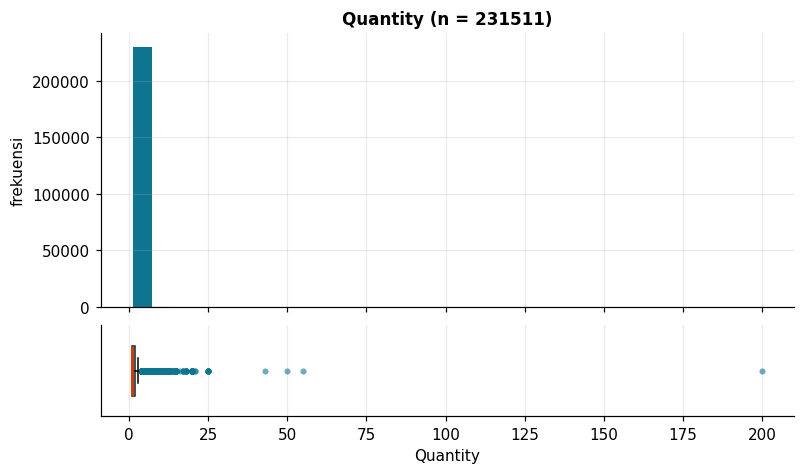

mean         1.56      median       1.00      selisih +0.56
std          1.20      IQR          1.00
skewness   23.615
outlier menurut batas IQR : 12954   (batas -0.50 .. 3.50)
outlier menurut |z| > 3   : 3121


In [4]:
import matplotlib as _mpl
_V = tuple(int(x) for x in _mpl.__version__.split('.')[:2])
ARAH = {'orientation': 'horizontal'} if _V >= (3, 10) else {'vert': False}   # kompatibel lintas versi

def potret(kolom, satuan=''):
    """Histogram + boxplot pada satu sumbu x, plus ringkasan angka."""
    d = df[kolom].dropna()
    q1, q3 = d.quantile([.25, .75]); iqr = q3 - q1
    bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = (d - d.mean()).abs() / d.std()

    fig, ax = plt.subplots(2, 1, figsize=(7.2, 4.2), sharex=True,
                           layout='constrained',
                           gridspec_kw={'height_ratios': [3, 1]})
    ax[0].hist(d, bins=32, color=DATA, edgecolor='white', linewidth=.6)
    ax[0].set_ylabel('frekuensi')
    ax[0].set_title(f'{kolom} (n = {len(d)})')
    ax[1].boxplot(d, **ARAH, widths=.55, patch_artist=True,
                  boxprops=dict(facecolor='#CFE8EF', edgecolor='#16202B'),
                  medianprops=dict(color=SOROT, linewidth=2),
                  flierprops=dict(marker='o', markersize=4, markerfacecolor=DATA,
                                  markeredgecolor='none', alpha=.6))
    ax[1].set_yticks([]); ax[1].set_xlabel(f'{kolom} {satuan}'.strip())
    plt.show()

    print(f'mean   {d.mean():10.2f}      median {d.median():10.2f}'
          f'      selisih {d.mean()-d.median():+.2f}')
    print(f'std    {d.std():10.2f}      IQR    {iqr:10.2f}')
    print(f'skewness {stats.skew(d):8.3f}')
    print(f'outlier menurut batas IQR : {((d<bawah)|(d>atas)).sum():4d}   '
          f'(batas {bawah:.2f} .. {atas:.2f})')
    print(f'outlier menurut |z| > 3   : {(z>3).sum():4d}')

potret(NUMERIK[0])

**Tafsiran variabel 1 (Quantity).** Distribusi sangat condong ke kanan (*right-skewed*), dibuktikan dengan ekor boxplot yang sangat panjang ke kanan serta nilai *skewness* ekstrem (23.61). Secara angka, mayoritas pelanggan hanya membeli 1-2 barang, tetapi terdapat transaksi bernilai sangat besar hingga 200 barang. Oleh karena itu, ukuran pemusatan yang lebih mewakili pola umum pelanggan adalah **median** (1.0), karena *mean* (1.56) terlalu sensitif dan ikut tertarik naik oleh pesanan grosir tersebut.

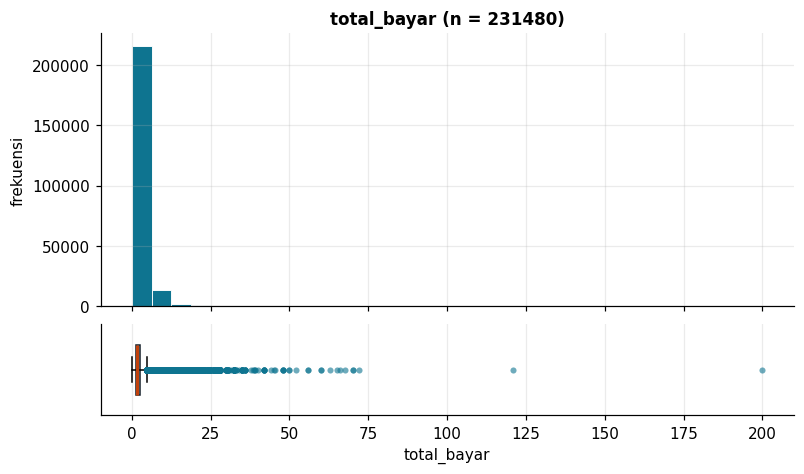

mean         2.43      median       1.60      selisih +0.83
std          2.57      IQR          1.40
skewness    6.587
outlier menurut batas IQR : 27531   (batas -0.90 .. 4.70)
outlier menurut |z| > 3   : 3922


In [5]:
potret(NUMERIK[1])

**Tafsiran variabel 2 (total_bayar).** Serupa dengan *Quantity*, distribusinya sangat menjulur ke kanan (*right-skewed*) dengan *skewness* 6.59. Sebagian besar pelanggan menghabiskan nominal yang kecil per pesanan, namun terdapat nilai ekstrem yang membuat rata-ratanya (*mean* 2.43) berada jauh di atas garis tengahnya. Karena kurva sangat asimetris, ukuran pemusatan **median** (1.60) lebih akurat dan realistis dalam mewakili pengeluaran tipikal pelanggan per pesanan.

## 2. Keputusan tentang outlier

Outlier **tidak otomatis dibuang**. Periksa dulu apakah nilainya sah.

| Variabel | Metode yang dipakai | Jumlah | Sah atau keliru? | Tindakan dan alasan |
|----------|---------------------|--------|------------------|---------------------|
| **Quantity** | Batas IQR (> 3.5) | 12.954 | Sebagian besar sah | **Dipertahankan**. Angka ekstrem (misal 50-200) wajar dalam bisnis *bakery* (kemungkinan pesanan katering/grosir/B2B). Akan ditandai untuk memisahkan analisis antara pelanggan ritel dan grosir. |
| **total_bayar** | Batas IQR (> 4.7) | 27.531 | Sah | **Dipertahankan**. Berkorelasi logis dengan besarnya *Quantity* atau pembelian produk-produk premium. |

Catatan: batas IQR cocok untuk distribusi yang menjulur; metode |z| > 3 mengandaikan
bentuk mendekati normal, dan mean serta std-nya sendiri ikut tertarik oleh outlier yang
sedang dicari. Bila batas bawah IQR bernilai negatif pada besaran yang tidak mungkin
negatif, batasi pada nol dan sebutkan bahwa itu konsekuensi aritmetika, bukan temuan.

In [6]:
# Menghitung batas atas IQR (batas bawah negatif tidak dipakai karena harga/kuantitas tidak mungkin < 0)
q1, q3 = df['Quantity'].quantile([0.25, 0.75])
atas_q = q3 + 1.5 * (q3 - q1)

t1, t3 = df['total_bayar'].quantile([0.25, 0.75])
atas_t = t3 + 1.5 * (t3 - t1)

# Tandai outlier dengan kolom penanda, jangan langsung dibuang
df['outlier_quantity'] = (df['Quantity'] > atas_q)
df['outlier_total_bayar'] = (df['total_bayar'] > atas_t)

## 3. Variabel kategorikal

In [7]:
KATEGORIKAL = ['article', 'bulan']      # TODO

for k in KATEGORIKAL:
    vc = df[k].value_counts()
    print(f'\n{k}  ({df[k].nunique()} nilai unik)')
    print((pd.DataFrame({'jumlah': vc, 'persen': (vc/len(df)*100).round(1)})
           .head(12).to_string()))


article  (148 nilai unik)
                      jumlah  persen
article                             
Traditional Baguette   67605    29.0
Coupe                  19618     8.4
Baguette               15281     6.6
Banette                15117     6.5
Croissant              11486     4.9
Pain Au Chocolat       10564     4.5
Special Bread           5184     2.2
Cereal Baguette         4950     2.1
Formule Sandwich        4191     1.8
Boule 400G              4084     1.8
Campagne                3894     1.7
Complet                 3133     1.3

bulan  (21 nilai unik)
         jumlah  persen
bulan                  
2021-08   20194     8.7
2022-08   20040     8.6
2022-07   18160     7.8
2021-07   17475     7.5
2021-05   12155     5.2
2022-05   11819     5.1
2021-04   10841     4.7
2021-06   10806     4.6
2022-06   10640     4.6
2021-09   10157     4.4
2022-04   10081     4.3
2021-10    9817     4.2


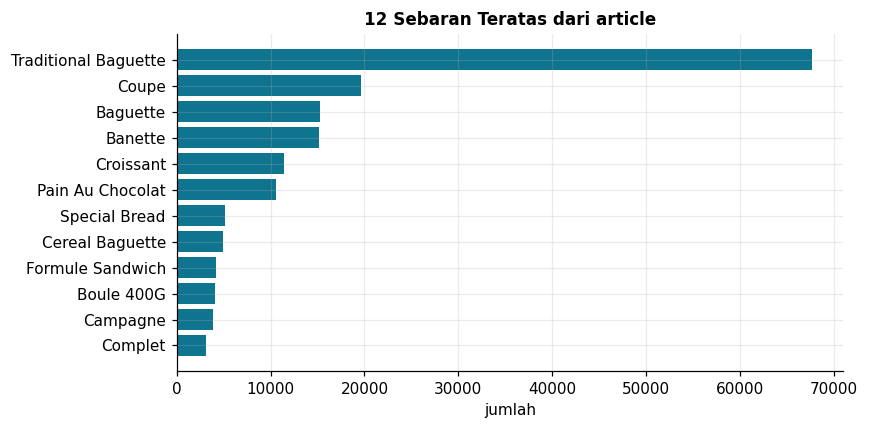

In [8]:
# Bar chart untuk kategori; urutkan menurut frekuensi, bukan abjad.
k = KATEGORIKAL[0]
vc = df[k].value_counts().head(12)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(vc.index[::-1], vc.values[::-1], color=DATA)
ax.set_xlabel('jumlah'); ax.set_title(f'12 Sebaran Teratas dari {k}')
plt.tight_layout(); plt.show()

**Tafsiran.** Ya, ada kategori yang sangat mendominasi. Pada variabel `article`, "Traditional Baguette" menyumbang lebih dari 67 ribu baris penjualan secara masif. Di sisi lain, dari total 148 jenis artikel, terdapat *long-tail* berisi banyak sekali kategori produk (seperti tartlet atau *pastry* spesifik) yang persentase penjualannya di bawah 0.5%. Statistik mereka menjadi kurang andal dan sebaiknya disatukan ke dalam kategori "Lainnya" (*Others*) pada analisis lanjutan. Pada variabel `bulan`, lonjakan terjadi secara musiman khususnya di bulan Juli dan Agustus.

## 4. Ringkasan temuan univariat

| Variabel | Bentuk distribusi | Pemusatan yang dipakai | Outlier | Catatan untuk analisis berikutnya |
|----------|-------------------|------------------------|---------|-----------------------------------|
| **Quantity** | Menjulur ke kanan | Median (1.0) | Banyak di ekor kanan | Lakukan segmentasi antara pesanan ritel harian vs. pesanan grosir (B2B) menggunakan kolom penanda *outlier*. |
| **total_bayar** | Menjulur ke kanan | Median (1.6) | Banyak di ekor kanan | Selidiki lebih lanjut produk apa yang mendorong pembengkakan transaksi di ekor kanan. |
| **article** | *Pareto* / *Long-tail* | Modus (Traditional Baguette) | - | Gabungkan produk dengan frekuensi sangat kecil ke satu label `Lain-lain` agar visualisasi bivariat tidak kotor. |
| **bulan** | Fluktuatif (Bimodal) | Modus (Agustus) | - | Fokuskan penelusuran *time-series* pada penyebab lonjakan setiap pertengahan tahun (Juli-Agustus). |

## Checklist sebelum mengumpulkan

- [x] Setiap variabel yang dianalisis memiliki tafsiran, bukan hanya grafik.
- [x] Bentuk distribusi dinyatakan dengan bukti dari gambar **dan** dari angka.
- [x] Pilihan mean atau median disertai alasan.
- [x] Keputusan tentang outlier dicatat beserta alasannya; tidak ada yang dibuang tanpa diperiksa.
- [x] Setiap grafik memiliki judul, label sumbu, dan satuan.
- [x] n yang dilaporkan adalah n setelah `dropna()`.
- [x] Restart & Run All berjalan tanpa galat.